# 06 · Cerebellum: do the treatments reverse aging?
**Question.** Do dietary restriction (**aDR**) and young plasma (**YMP**) push cerebellar gene expression back towards the young state?
**Input:** kallisto (02) and STAR (01) counts. **Output:** summary tables in `results/aging_vs_rejuvenation/`.
**Kernel:** **R** (`ir`) · **Time:** ~4 min (the first run downloads the MSigDB gene sets).

Everything is computed with **both** quantification methods (kallisto = primary, STAR = robustness check) through the same DESeq2 code. "Aging signal" = the changes between 21-month and 3-month mice; **reversal** = a treatment changes a gene or pathway in the opposite direction to aging.

| Analysis | Question |
|---|---|
| 2 | Which genes define aging (21 vs 3 months)? |
| 3 | Do treatment DEGs overlap aging DEGs, and in which direction? |
| 4 | Does a per-sample *aging-signature score* go down (rejuvenation) or up after treatment? |
| 5 | Which pathways change with aging, and are they reversed? |
| 6 | The paper's named gene sets in our cerebellum data |

**Caveats for every result:** 3–5 mice per group; treatments act at 19 months, aging is measured at 21 months; aDR is female-only, YMP male-only, aging mixed sex; the cohorts differ. Signature scores are z-scored within each treated/control pair, so batch differences between cohorts do not enter. P-values are indicative, not confirmatory. Terms: [docs/glossary.md](../docs/glossary.md).

## 1 · Setup
`fits` holds, per method, the DESeq2 models (`dds`) and result tables (`res`) for aging and both treatments; SRR21355389 is excluded from aging as in notebook 03.

In [1]:
# counts for both methods -> DESeq2 models and tables; summary of up / down DEGs per comparison
source('../R/helpers.R')
samples <- load_samples()
x <- load_txi(rownames(samples)); genes <- x$genes
counts <- list(kallisto = x$txi, STAR = load_star_counts()[, rownames(samples)])
fits <- lapply(counts, \(cn) { d <- run_dds(cn, samples); list(dds = d, res = de_tables(d, genes)) })   # same exclusion of SRR21355389 as notebook 03
bind_rows(lapply(fits, \(f) bind_rows(lapply(f$res, n_deg), .id = 'contrast')), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,109,31
kallisto,aging_21v3,79,52
kallisto,aDR,65,77
kallisto,YMP,19,19
STAR,aging_18v3,121,29
STAR,aging_21v3,102,72
STAR,aDR,75,121
STAR,YMP,10,13


## 2 · The aging signature (21 vs 3 months)
The aging DEGs (padj < 0.05), split by direction, are the signature used in analyses 3 and 4.

In [2]:
# numbers of aging-up and aging-down genes per method
sig <- lapply(fits, \(f) { a <- filter(f$res$aging_21v3, padj < 0.05); list(up = a$gene_id[a$log2FoldChange > 0], down = a$gene_id[a$log2FoldChange < 0]) })
tibble(method = names(sig), up = lengths(lapply(sig, `[[`, 'up')), down = lengths(lapply(sig, `[[`, 'down')))

method,up,down
<chr>,<int>,<int>
kallisto,79,52
STAR,102,72


## 3 · Overlap of treatment DEGs with aging DEGs
`shared` DEGs vs `expected_by_chance`; `shared_reversal` = opposite direction to aging (rejuvenating), `shared_same` = same direction (aging-like); `fisher_p` tests whether the overlap exceeds chance; `lfc_spearman_agingDEG` = correlation of log2FC with aging among aging DEGs (**negative = reversal**).

In [3]:
# overlap statistics per method and treatment
ov <- bind_rows(lapply(names(fits), \(m) bind_rows(lapply(c('aDR', 'YMP'), \(n)
  overlap_with_aging(fits[[m]]$res$aging_21v3, fits[[m]]$res[[n]]) %>% mutate(intervention = n))) %>% mutate(method = m))) %>% relocate(method, intervention)
ov

method,intervention,genes,aging_DEG,intervention_DEG,shared,expected_by_chance,shared_reversal,shared_same,fisher_p,lfc_spearman_all,lfc_spearman_agingDEG
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>
kallisto,aDR,15676,123,142,7,1.1,1,6,1.3e-04,0.145,0.420
kallisto,YMP,19192,130,36,3,0.2,3,0,1.8e-03,-0.131,-0.383
STAR,aDR,13703,158,196,14,2.3,1,13,5.9e-08,0.165,0.428
STAR,YMP,13228,157,23,3,0.3,3,0,2.4e-03,-0.207,-0.458


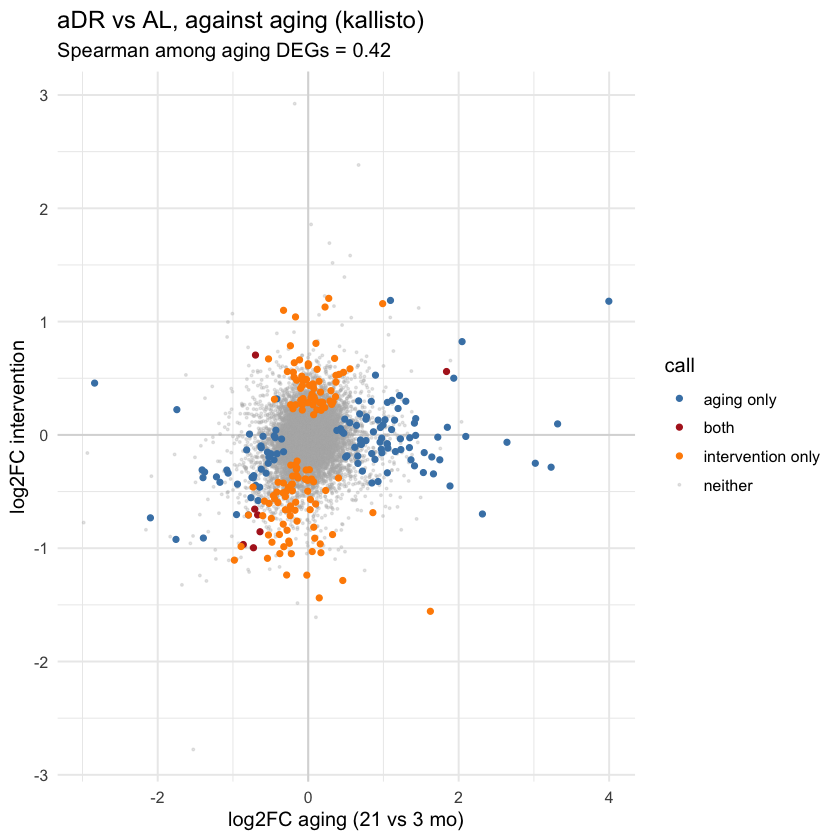

In [4]:
# each dot is a gene: log2FC in aging (x) vs in aDR (y); points on the diagonal move like aging
lfc_vs_aging_plot(fits$kallisto$res$aging_21v3, fits$kallisto$res$aDR, 'aDR vs AL, against aging (kallisto)')

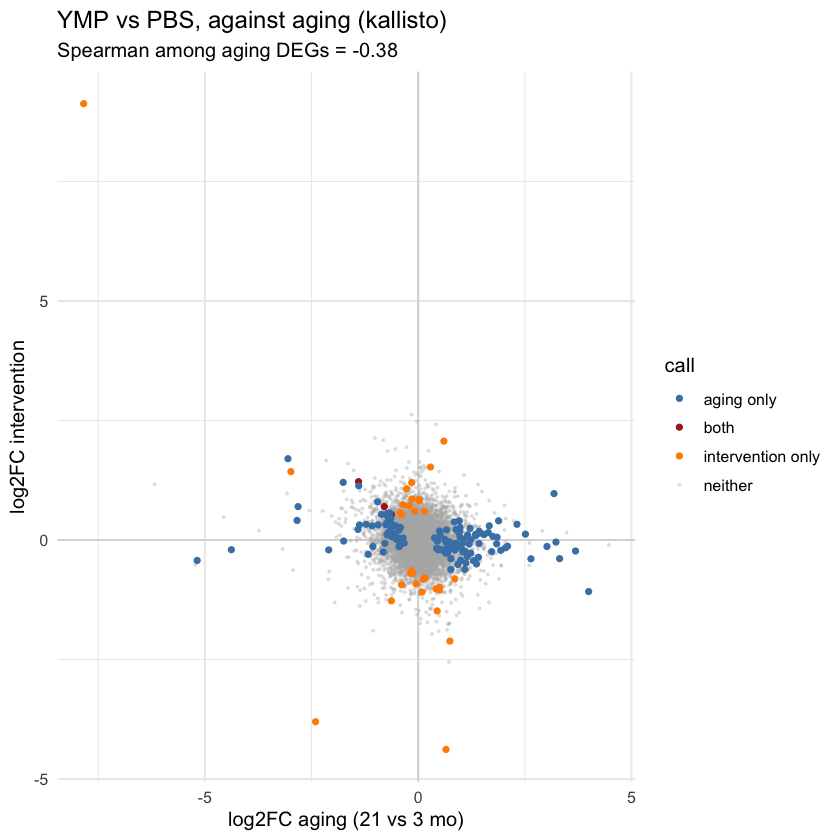

In [5]:
# the same for YMP: points in the upper-left / lower-right quadrants = reversal
lfc_vs_aging_plot(fits$kallisto$res$aging_21v3, fits$kallisto$res$YMP, 'YMP vs PBS, against aging (kallisto)')

## 4 · Aging-signature score per sample
Score = mean z-score of the aging-up genes minus mean z-score of the aging-down genes (z-score: expression relative to the mean and spread across the samples of the same experiment). The *aging* panel is a sanity check (the signature was derived from these mice); *aDR* and *YMP* are the test: a rejuvenating treatment should **lower** the score relative to its control.

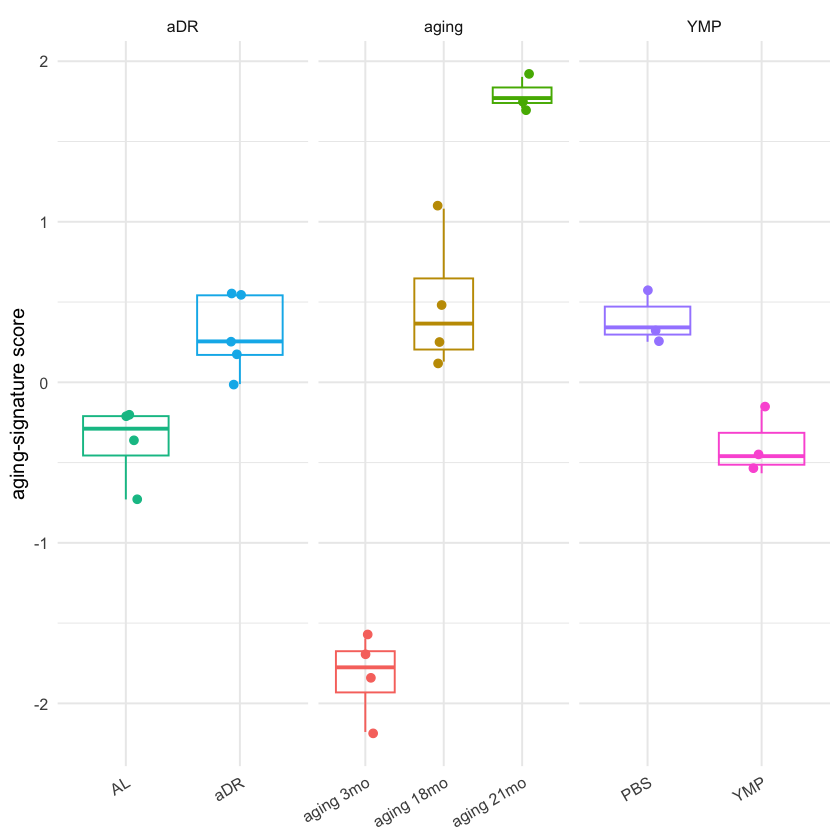

In [6]:
# score per mouse, by group (kallisto)
scores <- lapply(names(fits), \(m) lapply(fits[[m]]$dds, signature_score, up = sig[[m]]$up, down = sig[[m]]$down)) %>% setNames(names(fits))
score_plot(scores$kallisto)

In [7]:
# treated minus control (diff) with a Welch t-test, per method
score_tests <- bind_rows(lapply(names(scores), \(m) bind_rows(score_test(scores[[m]]$aDR, 'aDR', 'AL'), score_test(scores[[m]]$YMP, 'YMP', 'PBS')) %>% mutate(method = m))) %>% relocate(method)
score_tests

method,treated,control,n_t,n_c,diff,t_test_p
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>
kallisto,aDR,AL,5,4,0.680,0.0051
kallisto,YMP,PBS,3,3,-0.797,0.0076
STAR,aDR,AL,5,4,0.777,0.0160
STAR,YMP,PBS,3,3,-0.777,0.0340


`diff` < 0 = treated mice lower than control (rejuvenating direction). With 3–5 mice per group the t-test p-values are rough.

## 5 · Pathways (GSEA)
**GSEA** (gene set enrichment analysis, fgsea) ranks all genes by the DESeq2 Wald statistic of a comparison and tests whether a gene set (a list of genes with a shared function) sits mainly at the top (up-regulated) or bottom (down-regulated); **NES** is the resulting score (positive = up). Sets come from MSigDB: the 50 **Hallmark** sets and ~7,500 **GO biological-process** sets.

In [8]:
# GSEA for aging, aDR and YMP with both gene-set collections; counts of significant sets
sets <- msigdb_sets()
contrasts <- c('aging_21v3', 'aDR', 'YMP')
gs_h <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$hallmark))
gs_go <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$gobp))
bind_rows(lapply(names(gs_h), \(m) bind_rows(lapply(names(gs_h[[m]]), \(n) tibble(method = m, contrast = n, hallmark_sig = sum(gs_h[[m]][[n]]$padj < 0.05), gobp_sig = sum(gs_go[[m]][[n]]$padj < 0.05))))))

method,contrast,hallmark_sig,gobp_sig
<chr>,<chr>,<int>,<int>
kallisto,aging_21v3,18,488
kallisto,aDR,22,536
kallisto,YMP,20,149
STAR,aging_21v3,18,449
STAR,aDR,19,619
STAR,YMP,14,208


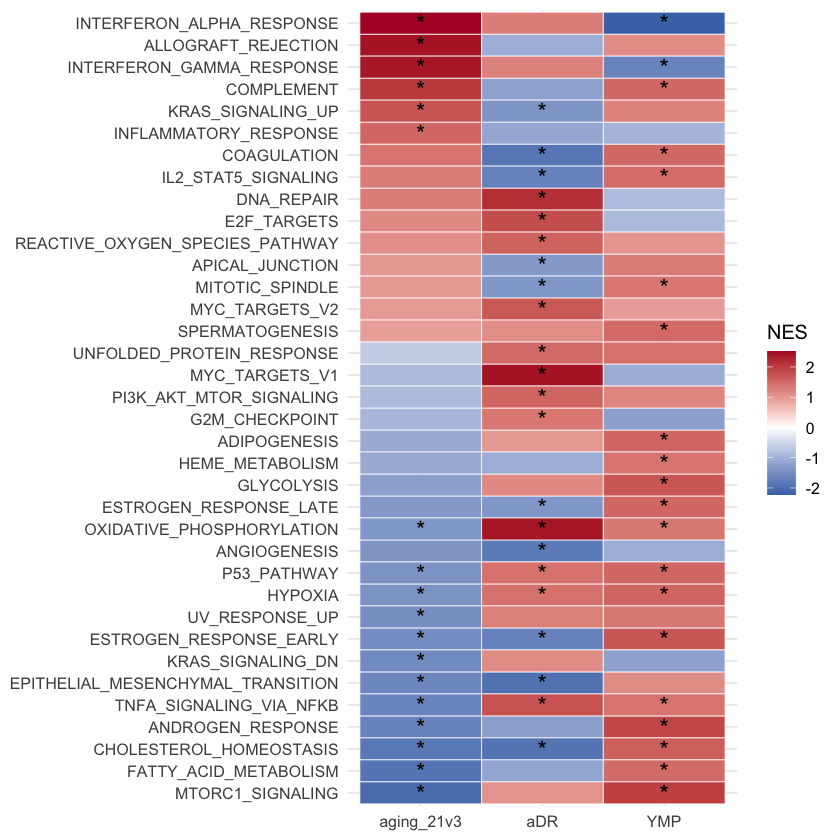

In [9]:
# Hallmark NES for aging vs the treatments (blue = down, red = up, * = padj < 0.05); opposite colours = reversal
nes_tiles(gs_h$kallisto)   # blue = down, red = up; * = padj < 0.05. Opposite colours between aging and a treatment = reversal

In [10]:
# of the sets significant in aging: how many does each treatment reverse (opposite NES) or mimic (same sign), both padj < 0.05
bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection')

collection,method,intervention,aging_sets,significant_in_both,reversed,same_direction,NES_spearman_all_sets
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>
Hallmark,kallisto,aDR,18,8,5,3,0.09
Hallmark,kallisto,YMP,18,12,11,1,-0.41
Hallmark,STAR,aDR,18,7,3,4,0.12
Hallmark,STAR,YMP,18,10,9,1,-0.45
GO_BP,kallisto,aDR,484,79,32,47,0.12
GO_BP,kallisto,YMP,485,34,29,5,-0.25
GO_BP,STAR,aDR,449,76,41,35,0.19
GO_BP,STAR,YMP,447,24,20,4,-0.21


## 6 · The paper's named gene sets in our cerebellum data
**Aging (CAS, Fig. 2B):** the 26 genes named in the figure; the full 82-gene list is in the paper's Table S1, which we do not have. **aDR (Fig. 6J):** the 23 genes the paper reports as aDR-regulated in at least 4 brain regions (circadian and cycling genes).

In [11]:
# the paper's aging genes: log2FC and padj in aging, aDR and YMP
cas <- c('Gpr17','Hsph1','Dnajb1','Chordc1','P4ha1','Ahsa1','Hist3h2a','C4b','H2-Q6','H2-Q7','Cirbp','Flt1','Tipin','Ctsz','Pcdhb14','Abca8a','Pcdhb8','Pcdhb6','Pcdhb9','H2-K1','Psmb8','Hvcn1','C1qa','Ctss','Tyrobp','Trem2')
adr23 <- c('Chordc1','Cxcl12','Fabp7','Kdr','Adipor2','Gjb6','Mertk','Cry1','Klf15','Dbp','Usp2','Etnppl','Ciart','Sult1a1','Zbtb16','Fkbp5','Sgk1','Tsc22d3','Cirbp','Rbm3','Plin4','Fmo2','Hif3a')
gene_table(fits$kallisto$res, cas) %>% arrange(padj_aging)

symbol,lfc_aging,padj_aging,lfc_aDR,padj_aDR,lfc_YMP,padj_YMP
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C4b,1.88,5.9e-18,-0.45,0.81000,0.40,1.000
H2-K1,0.93,2.2e-08,-0.41,0.43000,-0.11,1.000
Ctss,0.98,9.8e-08,-0.16,0.84000,0.26,1.000
H2-Q6,2.32,2.2e-07,-0.70,0.42000,0.33,1.000
Tyrobp,1.23,4.9e-06,-0.13,0.92000,-0.28,1.000
C1qa,1.06,2.0e-05,-0.12,0.92000,0.01,1.000
Ctsz,0.62,2.7e-05,-0.11,0.82000,0.01,1.000
Trem2,1.35,3.6e-05,-0.03,0.99000,0.09,1.000
Hsph1,-0.63,8.9e-05,-0.10,0.90000,0.53,0.042


In [12]:
# the paper's aDR genes: how many go up with aDR in our data, and how many are significant
bind_rows(lapply(fits, \(f) { t <- gene_table(f$res, adr23); tibble(genes = nrow(t), up_in_aDR = sum(t$lfc_aDR > 0), significant_aDR = sum(t$padj_aDR < 0.05, na.rm = TRUE)) }), .id = 'method')

method,genes,up_in_aDR,significant_aDR
<chr>,<int>,<int>,<int>
kallisto,23,19,11
STAR,23,19,18


## 7 · Save
Small summary tables for the report.

In [13]:
# writes results/aging_vs_rejuvenation/*.csv
dir.create(file.path(ROOT, 'results/aging_vs_rejuvenation'), showWarnings = FALSE)
out <- file.path(ROOT, 'results/aging_vs_rejuvenation')
write_csv(ov, file.path(out, 'overlap_with_aging.csv')); write_csv(score_tests, file.path(out, 'signature_score_tests.csv'))
write_csv(bind_rows(lapply(gs_h, \(g) bind_rows(g, .id = 'contrast')), .id = 'method'), file.path(out, 'gsea_hallmark.csv'))
write_csv(bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection'), file.path(out, 'gsea_concordance.csv'))
write_csv(gene_table(fits$kallisto$res, cas), file.path(out, 'paper_CAS_named_genes.csv'))
list.files(out)

[1] "gsea_concordance.csv"      "gsea_hallmark.csv"        
[3] "overlap_with_aging.csv"    "paper_CAS_named_genes.csv"
[5] "signature_score_tests.csv"